# 12. Recurring Expense and Income Retention

This notebook tests whether recurring regional expenses make development compete more with environmental investment. I vary only the share of post-damage income that becomes spendable currency.

## Income available to spend

Each year, the environment calculates gross income and applies the existing environmental damage fraction. The remaining income is `net_income`. I apply a retention fraction `r` to that amount:

`retained_income = r * net_income`

`recurring_expense = (1 - r) * net_income`

Only retained income is added to regional currency. The environmental-damage productivity carry-forward continues to use its current formula, independent of recurring expenses. This isolates a recurring cash expense from a productivity penalty.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from study_3_pollutant_dynamics.baseline_regression import (REFERENCE_BASELINE_SETTINGS, REFERENCE_BASELINE_POLICIES,
                                                            compare_reference_baseline)
from study_3_pollutant_dynamics.config import EnvironmentConfig
from study_3_pollutant_dynamics.economic_parameters import REGIONAL_ECONOMIC_PARAMETERS
from study_3_pollutant_dynamics.integrated_environment import Study3IntegratedEnvironment
from study_3_pollutant_dynamics.policy_evaluation import (FIXED_POLICY_NAMES, run_fixed_policy_episode,
                                                          summarize_integrated_episode)
from study_3_pollutant_dynamics.scenario_parameters import get_parameters

## Test settings

I use the quadratic development-cost curve, the proposed starting currency, reference pollutant and damage settings, and the existing project schedule. The fixed policies are development-only, balanced, and cleanup-focused.

In [2]:
def collect_retention_income(trajectory, retention_fraction, policy_name, horizon):
    annual_rows = []

    cumulative_gross_income = 0.0
    cumulative_net_income = 0.0
    cumulative_retained_income = 0.0
    cumulative_expenses = 0.0

    for info in trajectory:
        year = info["regional_economy"][0]["year"]

        year_gross_income = 0.0
        year_net_income = 0.0
        year_retained_income = 0.0
        year_recurring_expense = 0.0

        for region_result in info["regional_economy"]:
            gross_income = region_result["gross_income"]
            net_income = region_result["net_income"]
            retained_income = region_result["retained_income"]
            recurring_expense = region_result["recurring_expense"]

            cumulative_gross_income += gross_income
            cumulative_net_income += net_income
            cumulative_retained_income += retained_income
            cumulative_expenses += recurring_expense

            year_gross_income += gross_income
            year_net_income += net_income
            year_retained_income += retained_income
            year_recurring_expense += recurring_expense

        row = {
            "retention_fraction": retention_fraction,
            "policy": policy_name,
            "horizon_years": horizon,
            "year": year,
            "gross_income_all_regions": year_gross_income,
            "net_income_all_regions": year_net_income,
            "retained_income_all_regions": year_retained_income,
            "recurring_expenses_all_regions": year_recurring_expense,
        }

        annual_rows.append(row)

    cumulative_results = {
        "gross_income": cumulative_gross_income,
        "net_income": cumulative_net_income,
        "retained_income": cumulative_retained_income,
        "recurring_expenses": cumulative_expenses,
    }

    return annual_rows, cumulative_results

In [3]:
def collect_retention_regional_results(trajectory, environment, retention_fraction, policy_name):
    regional_rows = []

    for region_index, region_parameters in enumerate(REGIONAL_ECONOMIC_PARAMETERS):
        regional_income = 0.0
        regional_retained = 0.0
        regional_expenses = 0.0

        development_requests = 0
        affordable_development = 0
        completed_packages = 0
        lowest_cash_cost_ratio = float("inf")

        for info in trajectory:
            region_result = info["regional_economy"][region_index]

            regional_income += region_result["net_income"]
            regional_retained += region_result["retained_income"]
            regional_expenses += region_result["recurring_expense"]

            if region_result["development_requested"]:
                development_requests += 1

                if region_result["development_affordable"]:
                    affordable_development += 1

                requested_cost = region_result["development_requested_cost"]
                opening_currency = region_result["currency_before_actions"]
                cash_cost_ratio = opening_currency / requested_cost

                if cash_cost_ratio < lowest_cash_cost_ratio:
                    lowest_cash_cost_ratio = cash_cost_ratio

            if region_result["package_purchased"]:
                completed_packages += 1

        first_region_result = trajectory[0]["regional_economy"][region_index]
        final_region_result = trajectory[-1]["regional_economy"][region_index]

        row = {
            "retention_fraction": retention_fraction,
            "policy": policy_name,
            "region": region_parameters["region"],
            "starting_currency": region_parameters["initial_currency"] * STARTING_CURRENCY_MULTIPLIER,
            "starting_annual_income": region_parameters["annual_income"],
            "annual_growth_rate": region_parameters["annual_income_growth_rate"],
            "year_1_net_income": first_region_result["net_income"],
            "year_60_net_income": final_region_result["net_income"],
            "mean_annual_net_income": regional_income / 60,
            "mean_annual_retained_income": regional_retained / 60,
            "mean_annual_recurring_expense": regional_expenses / 60,
            "cumulative_net_income": regional_income,
            "retained_income": regional_retained,
            "recurring_expenses": regional_expenses,
            "development_requests": development_requests,
            "affordable_development": affordable_development,
            "unaffordable_development": development_requests - affordable_development,
            "minimum_opening_currency_to_cost_ratio": lowest_cash_cost_ratio,
            "development_spending": environment.development_spending[region_index],
            "mitigation_spending": environment.investment_spending[region_index],
            "completed_packages": completed_packages,
            "final_EDI": environment.edi[region_index],
            "final_currency": environment.currency[region_index],
            "final_net_income": final_region_result["net_income"],
        }

        regional_rows.append(row)

    return regional_rows

In [4]:
RETENTION_FRACTIONS = [0.2, 0.4, 0.6, 0.8, 1.0]
HORIZONS = [20, 40, 60]
COST_SHAPE = "quadratic"

POLICIES = []

for policy_name in FIXED_POLICY_NAMES:
    if policy_name in REFERENCE_BASELINE_POLICIES:
        POLICIES.append(policy_name)

STARTING_CURRENCY_MULTIPLIER = REFERENCE_BASELINE_SETTINGS["starting_currency_multiplier"]
SEED = REFERENCE_BASELINE_SETTINGS["seed"]
PURCHASE_FREQUENCY_YEARS = 5

experiment_rows = []
regional_rows = []
annual_rows = []
retention_trajectories = {}

for retention_fraction in RETENTION_FRACTIONS:
    for policy_name in POLICIES:
        for horizon in HORIZONS:
            parameters = get_parameters(episode_steps=horizon)
            config = EnvironmentConfig(parameters)

            environment = Study3IntegratedEnvironment(
                config,
                starting_currency_multiplier=STARTING_CURRENCY_MULTIPLIER,
                development_cost_shape=COST_SHAPE,
                development_cost_multiplier=REFERENCE_BASELINE_SETTINGS["development_cost_multiplier"],
                investment_cost_multiplier=REFERENCE_BASELINE_SETTINGS["investment_cost_multiplier"],
                income_damage_multiplier=REFERENCE_BASELINE_SETTINGS["income_damage_multiplier"],
                income_damage_persistence=REFERENCE_BASELINE_SETTINGS["income_damage_persistence"],
                income_retention_fraction=retention_fraction,
            )

            trajectory, terminated, truncated = run_fixed_policy_episode(policy_name, environment, seed=SEED)

            summary = summarize_integrated_episode(policy_name, trajectory, environment)

            policy_annual_rows, cumulative_results = collect_retention_income(trajectory, retention_fraction, policy_name, horizon)

            annual_rows.extend(policy_annual_rows)

            planned_cycles = 0

            if policy_name in ("balanced", "cleanup_focused"):
                cycles_per_region = (horizon + PURCHASE_FREQUENCY_YEARS - 1) // PURCHASE_FREQUENCY_YEARS
                planned_cycles = cycles_per_region * len(environment.regions)

            summary["retention_fraction"] = retention_fraction
            summary["horizon_years"] = horizon
            summary["cumulative_gross_income"] = cumulative_results["gross_income"]
            summary["cumulative_net_income"] = cumulative_results["net_income"]
            summary["cumulative_retained_income"] = cumulative_results["retained_income"]
            summary["cumulative_recurring_expenses"] = cumulative_results["recurring_expenses"]
            summary["mean_retained_income_per_region_year"] = cumulative_results["retained_income"] / (horizon * len(environment.regions))
            summary["planned_purchase_cycles"] = planned_cycles
            summary["missed_purchase_cycles"] = max(0, planned_cycles - summary["investment_package_purchases"])
            summary["terminated"] = terminated
            summary["completed_horizon"] = truncated

            experiment_rows.append(summary)

            retention_trajectories[(retention_fraction, policy_name, horizon)] = trajectory

            if horizon == 60:
                policy_regional_rows = collect_retention_regional_results(trajectory, environment, retention_fraction, policy_name)
                regional_rows.extend(policy_regional_rows)

In [5]:
experiment_results = pd.DataFrame(experiment_rows)
regional_results = pd.DataFrame(regional_rows)
annual_income_results = pd.DataFrame(annual_rows)

print(f"Completed {len(experiment_results)} deterministic episodes.")

Completed 45 deterministic episodes.


## Retained-income accounting check

For each region-year, retained income plus recurring expenses should equal net income after environmental damage. This check covers all 45 episodes and verifies the budget split before interpreting affordability.

In [6]:
accounting_checks = []

for retention_fraction in RETENTION_FRACTIONS:
    for policy_name in POLICIES:
        for horizon in HORIZONS:
            trajectory = retention_trajectories[(retention_fraction, policy_name, horizon)]
            for info in trajectory:
                for region_result in info["regional_economy"]:
                    net_income = region_result["net_income"]
                    retained_income = region_result["retained_income"]
                    recurring_expense = region_result["recurring_expense"]
                    split_residual = abs(net_income - retained_income - recurring_expense)
                    expected_retained_income = net_income * retention_fraction
                    retained_residual = abs(retained_income - expected_retained_income)
                    accounting_checks.append({
                        "retention_fraction": retention_fraction,
                        "policy": policy_name,
                        "year": region_result["year"],
                        "income_split_passed": split_residual < 1e-9,
                        "retention_rate_passed": retained_residual < 1e-9,
                    })

In [7]:
accounting_check_results = pd.DataFrame(accounting_checks)
passed_split_checks = int(accounting_check_results["income_split_passed"].sum())
passed_rate_checks = int(accounting_check_results["retention_rate_passed"].sum())
check_count = len(accounting_check_results)

display(pd.DataFrame({"check": ["retained income + expense = net income", "retained income = fraction * net income"],
                      "passed": [passed_split_checks, passed_rate_checks],
                      "total": [check_count, check_count]}))

if passed_split_checks != check_count or passed_rate_checks != check_count:
    raise ValueError("Recurring-expense accounting check failed.")

,check,passed,total
0,retained income + expense = net income,7200,7200
1,retained income = fraction * net income,7200,7200


## Final outcomes by retention level

Compare final EDI and currency with recurring expenses, development spending, and mitigation purchases. An unaffordable development attempt means the region could not pay for the requested point from its opening balance. An investment attempt may be retried in a later year; the completed and missed cycle counts show whether it was ultimately purchased.

In [8]:
summary_columns = [
    "retention_fraction", "policy", "horizon_years", "final_mean_EDI", "final_min_EDI",
    "cumulative_net_income", "cumulative_retained_income", "cumulative_recurring_expenses",
    "development_spending", "mitigation_spending", "investment_package_purchases",
    "missed_purchase_cycles", "unaffordable_development_attempts",
    "unaffordable_investment_attempts", "final_mean_currency",
]
display(experiment_results[summary_columns].round(3))

,retention_fraction,policy,horizon_years,final_mean_EDI,final_min_EDI,cumulative_net_income,cumulative_retained_income,cumulative_recurring_expenses,development_spending,mitigation_spending,investment_package_purchases,missed_purchase_cycles,unaffordable_development_attempts,unaffordable_investment_attempts,final_mean_currency
0,0.2,development_only,20,85.00,75.0,7111.032,1422.206,5688.825,3381.776,0.0,0,0,0,0,135.107
1,0.2,development_only,40,91.50,82.0,16084.426,3216.885,12867.541,5227.634,0.0,0,0,45,0,122.313
2,0.2,development_only,60,94.75,88.0,25038.703,5007.741,20030.962,6190.524,0.0,0,0,78,0,329.304
3,0.2,cleanup_focused,20,81.75,71.0,7215.434,1443.087,5772.347,2652.735,1100.0,11,5,13,25,47.588
4,0.2,cleanup_focused,40,89.25,80.0,16829.236,3365.847,13463.388,4555.445,1100.0,11,21,63,105,52.600
5,0.2,cleanup_focused,60,94.00,87.0,27419.559,5483.912,21935.647,5966.374,1600.0,16,32,101,166,104.384
6,0.2,balanced,20,80.50,71.0,7320.494,1464.099,5856.395,2372.583,1400.0,7,9,18,45,47.879
7,0.2,balanced,40,88.25,80.0,17042.382,3408.476,13633.906,4264.082,1400.0,7,25,67,125,61.099
8,0.2,balanced,60,93.75,87.0,27752.160,5550.432,22201.728,5894.124,1800.0,9,39,108,197,89.077
9,0.4,development_only,20,85.00,75.0,7111.032,2844.413,4266.619,3381.776,0.0,0,0,0,0,490.659


## 60-year affordability summary

This table focuses on the longest horizon, where every region has enough time to attempt all remaining development points. It shows whether lower retained income affects EDI, purchase completion, or currency.

In [9]:
year_60_results = experiment_results[experiment_results["horizon_years"] == 60]
year_60_columns = ["retention_fraction", "policy", "final_mean_EDI", "final_min_EDI",
                   "cumulative_net_income", "cumulative_retained_income", "cumulative_recurring_expenses",
                   "development_spending", "mitigation_spending", "investment_package_purchases",
                   "missed_purchase_cycles", "unaffordable_development_attempts",
                   "unaffordable_investment_attempts", "final_mean_currency",
                   "final_CO2_ppm", "final_mean_PM2.5_ug_m3",
                   "final_mean_nitrate_mg_N_L", "final_mean_lead_total_kg"]
display(year_60_results[year_60_columns].round(3))

,retention_fraction,policy,final_mean_EDI,final_min_EDI,cumulative_net_income,cumulative_retained_income,cumulative_recurring_expenses,development_spending,mitigation_spending,investment_package_purchases,missed_purchase_cycles,unaffordable_development_attempts,unaffordable_investment_attempts,final_mean_currency,final_CO2_ppm,final_mean_PM2.5_ug_m3,final_mean_nitrate_mg_N_L,final_mean_lead_total_kg
2,0.2,development_only,94.75,88.0,25038.703,5007.741,20030.962,6190.524,0.0,0,0,78,0,329.304,581.594,8.608,3.090,19.709
5,0.2,cleanup_focused,94.00,87.0,27419.559,5483.912,21935.647,5966.374,1600.0,16,32,101,166,104.384,581.027,8.606,3.004,17.566
8,0.2,balanced,93.75,87.0,27752.160,5550.432,22201.728,5894.124,1800.0,9,39,108,197,89.077,580.447,8.597,2.919,18.068
11,0.4,development_only,100.00,100.0,24343.079,9737.231,14605.847,8017.169,0.0,0,0,30,0,1055.016,582.739,8.616,3.269,19.940
14,0.4,cleanup_focused,99.75,99.0,27689.839,11075.936,16613.903,7919.379,2900.0,29,19,46,97,689.139,582.260,8.616,3.191,15.819
17,0.4,balanced,99.75,99.0,27964.862,11185.945,16778.917,7919.379,4000.0,20,28,48,143,441.641,581.140,8.598,2.969,16.591
20,0.6,development_only,100.00,100.0,24165.780,14499.468,9666.312,8017.169,0.0,0,0,0,0,2245.575,582.977,8.616,3.270,19.990
23,0.6,cleanup_focused,100.00,100.0,27540.086,16524.051,11016.034,8017.169,4300.0,43,5,9,30,1676.721,582.761,8.616,3.148,14.233
26,0.6,balanced,100.00,100.0,28749.148,17249.489,11499.659,8017.169,6600.0,33,15,8,82,1283.080,580.306,8.572,2.494,14.682
29,0.8,development_only,100.00,100.0,24165.780,19332.624,4833.156,8017.169,0.0,0,0,0,0,3453.864,582.977,8.616,3.270,19.990


## Regional income and affordability at year 60

This table separates the regional starting resources from income generated during the episode. The minimum opening-currency-to-cost ratio shows how close a development request came to being unaffordable.

In [10]:
regional_columns = ["retention_fraction", "policy", "region", "starting_currency",
                    "starting_annual_income", "annual_growth_rate", "year_1_net_income",
                    "year_60_net_income", "mean_annual_net_income",
                    "mean_annual_retained_income", "mean_annual_recurring_expense",
                    "cumulative_net_income", "retained_income", "recurring_expenses",
                    "development_spending", "mitigation_spending", "development_requests",
                    "unaffordable_development", "minimum_opening_currency_to_cost_ratio", "completed_packages",
                    "final_EDI", "final_currency", "final_net_income"]
display(regional_results[regional_columns].round(3))

,retention_fraction,policy,region,starting_currency,starting_annual_income,annual_growth_rate,year_1_net_income,year_60_net_income,mean_annual_net_income,mean_annual_retained_income,...,recurring_expenses,development_spending,mitigation_spending,development_requests,unaffordable_development,minimum_opening_currency_to_cost_ratio,completed_packages,final_EDI,final_currency,final_net_income
0,0.2,development_only,Northeast,700.0,65.0,0.015,65.971,123.025,116.600,23.320,...,5596.795,1712.639,0.0,46,16,0.338,0,100.0,386.560,123.025
1,0.2,development_only,Midwest,550.0,55.0,0.012,53.967,77.613,84.620,16.924,...,4061.765,1503.984,0.0,60,29,0.311,0,91.0,61.457,77.613
2,0.2,development_only,South,450.0,50.0,0.020,50.605,93.857,98.758,19.752,...,4740.362,1552.901,0.0,60,27,0.335,0,88.0,82.189,93.857
3,0.2,development_only,West,800.0,75.0,0.018,76.345,124.104,117.334,23.467,...,5632.040,1421.000,0.0,31,6,0.445,0,100.0,787.010,124.104
4,0.2,cleanup_focused,Northeast,700.0,65.0,0.015,65.971,151.125,126.197,25.239,...,6057.442,1712.639,400.0,55,25,0.362,4,100.0,101.722,151.125
5,0.2,cleanup_focused,Midwest,550.0,55.0,0.012,53.967,99.671,95.398,19.080,...,4579.095,1353.031,300.0,60,31,0.293,3,89.0,41.742,99.671
6,0.2,cleanup_focused,South,450.0,50.0,0.020,50.605,116.268,108.420,21.684,...,5204.152,1479.704,200.0,60,28,0.335,2,87.0,71.334,116.268
7,0.2,cleanup_focused,West,800.0,75.0,0.018,76.345,152.841,126.978,25.396,...,6094.958,1421.000,700.0,42,17,0.315,7,100.0,202.739,152.841
8,0.2,balanced,Northeast,700.0,65.0,0.015,65.971,155.939,127.013,25.403,...,6096.629,1712.639,400.0,58,28,0.414,2,100.0,111.518,155.939
9,0.2,balanced,Midwest,550.0,55.0,0.012,53.967,104.601,98.560,19.712,...,4730.867,1280.781,400.0,60,32,0.338,2,88.0,51.935,104.601


## Income retained over time

The table summarizes annual income for the 60-year episodes. Gross income reflects the regional income equation, and net income is after environmental damage. The retained amount is what enters currency after recurring expenses.

In [11]:
annual_income_60 = annual_income_results[annual_income_results["horizon_years"] == 60]
annual_income_summary = annual_income_60.groupby(["retention_fraction", "policy"]).agg(
    mean_annual_net_income=("net_income_all_regions", "mean"),
    mean_annual_retained_income=("retained_income_all_regions", "mean"),
    mean_annual_recurring_expenses=("recurring_expenses_all_regions", "mean"),
).reset_index()

display(annual_income_summary.round(3))

,retention_fraction,policy,mean_annual_net_income,mean_annual_retained_income,mean_annual_recurring_expenses
0,0.2,balanced,462.536,92.507,370.029
1,0.2,cleanup_focused,456.993,91.399,365.594
2,0.2,development_only,417.312,83.462,333.849
3,0.4,balanced,466.081,186.432,279.649
4,0.4,cleanup_focused,461.497,184.599,276.898
5,0.4,development_only,405.718,162.287,243.431
6,0.6,balanced,479.152,287.491,191.661
7,0.6,cleanup_focused,459.001,275.401,183.601
8,0.6,development_only,402.763,241.658,161.105
9,0.8,balanced,508.572,406.857,101.714


## What the 60-year comparison shows

At 100% retention, all three policies reach EDI 100 and buy every scheduled mitigation package. At 80%, development still reaches EDI 100, but balanced completes 47 of 48 packages. At 60%, all policies still reach EDI 100, while balanced completes 33 packages and cleanup-focused completes 43. This creates a clear mitigation-budget trade-off without preventing development from reaching its target.

At 40%, development-only reaches EDI 100, while balanced and cleanup-focused finish at mean EDI 99.75. Balanced completes 20 of 48 packages and cleanup-focused completes 29. At 20%, all policies finish below EDI 95 on average; balanced completes 9 packages and has 108 unaffordable development attempts. This is a much tighter budget case and may be too severe as a reference setting.

The middle of this tested range (40% to 60% retained) is the most useful area for follow-up: it produces differences in affordability and mitigation coverage while still allowing regions to reach or nearly reach EDI 100. These fractions are design scenarios, not empirically established expense rates. The table's pollution outcomes should be considered alongside completed packages before selecting a setting.

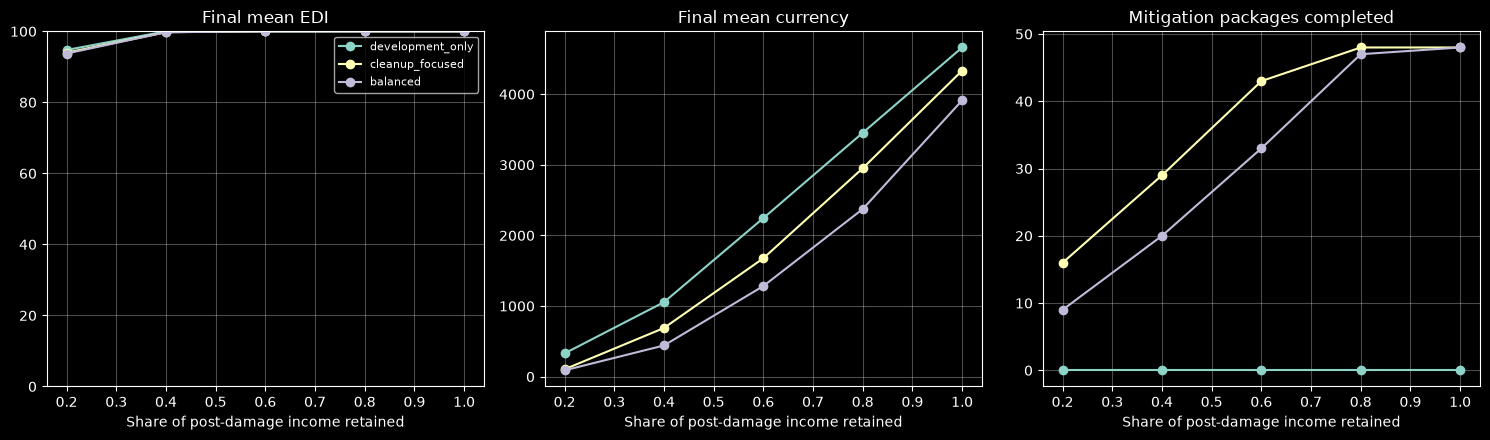

In [12]:
year_60_results = experiment_results[experiment_results["horizon_years"] == 60]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for policy_name in POLICIES:
    policy_rows = year_60_results[year_60_results["policy"] == policy_name]
    axes[0].plot(policy_rows["retention_fraction"], policy_rows["final_mean_EDI"], marker="o", label=policy_name)
    axes[1].plot(policy_rows["retention_fraction"], policy_rows["final_mean_currency"], marker="o", label=policy_name)
    axes[2].plot(policy_rows["retention_fraction"], policy_rows["investment_package_purchases"], marker="o", label=policy_name)

axes[0].set_title("Final mean EDI")
axes[1].set_title("Final mean currency")
axes[2].set_title("Mitigation packages completed")

for axis in axes:
    axis.set_xlabel("Share of post-damage income retained")
    axis.grid(alpha=0.3)
axes[0].set_ylim(0, 100)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Default-environment regression check

The retained-income setting defaults to 100%. This check reruns the shared constant-cost, 40-year reference case and compares it with the same regression values used in Notebooks 09 and 10. It confirms that adding the option did not change the default results.

In [13]:
default_config = EnvironmentConfig(get_parameters(episode_steps=REFERENCE_BASELINE_SETTINGS["episode_steps"]))
default_rows = []
for policy_name in REFERENCE_BASELINE_POLICIES:
    default_environment = Study3IntegratedEnvironment(default_config,
        starting_currency_multiplier=REFERENCE_BASELINE_SETTINGS["starting_currency_multiplier"],
        development_cost_shape=REFERENCE_BASELINE_SETTINGS["development_cost_shape"],
        development_cost_multiplier=REFERENCE_BASELINE_SETTINGS["development_cost_multiplier"],
        investment_cost_multiplier=REFERENCE_BASELINE_SETTINGS["investment_cost_multiplier"],
        income_damage_multiplier=REFERENCE_BASELINE_SETTINGS["income_damage_multiplier"],
        income_damage_persistence=REFERENCE_BASELINE_SETTINGS["income_damage_persistence"],
        income_retention_fraction=1.0)

    trajectory, terminated, truncated = run_fixed_policy_episode(policy_name,
                                                                 default_environment,                                         seed=REFERENCE_BASELINE_SETTINGS["seed"])

    default_row = summarize_integrated_episode(policy_name, trajectory, default_environment)
    default_rows.append(default_row)

In [14]:
default_check_rows = compare_reference_baseline(default_rows)
default_checks = pd.DataFrame(default_check_rows)
display(default_checks)

passed_checks = int(default_checks["passed"].sum())
total_checks = len(default_checks)
print(f"Passed {passed_checks} of {total_checks} default-environment regression checks.")

if passed_checks != total_checks:
    raise ValueError("Default environment changed; review the change and update the shared regression baseline only if intended.")

,policy,metric,expected,actual,passed
0,development_only,final_mean_EDI,98.750000,98.750000,True
1,development_only,final_min_EDI,95.000000,95.000000,True
2,development_only,final_mean_currency,3744.507401,3744.507401,True
3,development_only,minimum_currency,475.605311,475.605311,True
4,development_only,development_spending,3375.000000,3375.000000,True
5,development_only,mitigation_spending,0.000000,0.000000,True
6,development_only,investment_package_purchases,0.000000,0.000000,True
7,development_only,unaffordable_development_attempts,0.000000,0.000000,True
8,development_only,final_CO2_ppm,529.662055,529.662055,True
9,development_only,final_mean_PM2.5_ug_m3,8.613520,8.613520,True


Passed 36 of 36 default-environment regression checks.


## Interpretation and limits

Use the tables to identify when retained income starts limiting development or scheduled environmental purchases. A lower final EDI is not automatically a failure of the policy; it may show that recurring expenses leave fewer resources for development. Likewise, missed project cycles indicate affordability pressure under this fixed purchase rule, not that the environment is impossible to manage.

The retention fractions are exploratory budget assumptions, not measured regional expense rates. This test changes only income credited to currency. It does not model which services the recurring expenses provide, shocks, or income losses to future productivity. No agents are trained.